In [1]:
import requests
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

api_url='https://xray-api.renecol.org'
token='eR2GTCvSUAXvgu8KyDm5xeieSjPF3H'
image_suffix='/api/imagedata/'
response1 = requests.get(headers={'Authorization': 'Bearer ' + token},url=api_url+image_suffix).json()
response2 = requests.get(headers={'Authorization': 'Bearer ' + token},url=api_url+image_suffix, params={'complete':True}).json()
df1 = pd.DataFrame(response1)
df2 = pd.DataFrame(response2)
df1a = df1[['id','patient_id','n_measurements','measure_dataset','referring_patient','img_type','acquisition_date']]
df2a = df2[['id','patient_id','n_measurements','measure_dataset','referring_patient','img_type','acquisition_date']]

# discard example Patients
exampleString = 'example'
df1bfilter = df1a['patient_id'].str.contains(exampleString)
df1b=df1a[~df1bfilter]
df2bfilter = df2a['patient_id'].str.contains(exampleString)
df2b=df2a[~df2bfilter]

<Axes: xlabel='n_measurements', ylabel='count'>

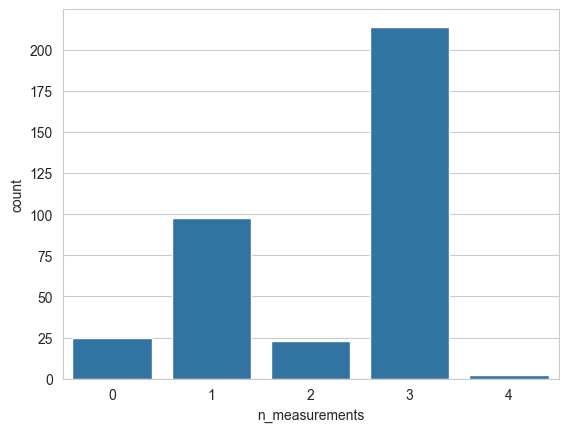

In [3]:
sns.countplot(df2b,x='n_measurements')

/var/folders/v5/10wd6_3x1xz6vdd_jj69w80r0000gn/T/ipykernel_47082/3306912436.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1b.loc[:,'dataset']='userview'
/var/folders/v5/10wd6_3x1xz6vdd_jj69w80r0000gn/T/ipykernel_47082/3306912436.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2b.loc[:,'dataset']='complete'


<Axes: xlabel='n_measurements', ylabel='count'>

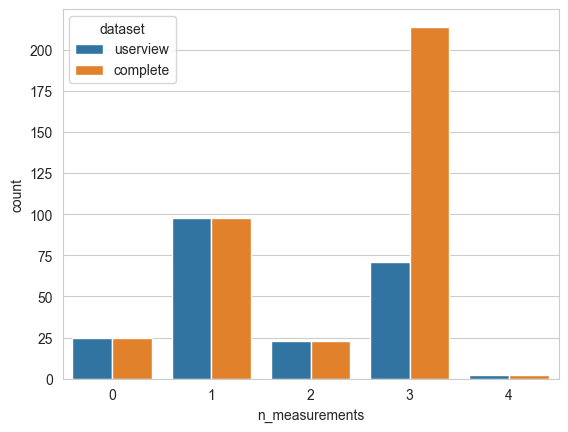

In [4]:
df1b.loc[:,'dataset']='userview'
df2b.loc[:,'dataset']='complete'
df_complete=pd.concat([df1b,df2b])
sns.countplot(df_complete,x='n_measurements', hue='dataset')

In [5]:
indicesAtLeastOneMeasure = df2b.loc[df2b['n_measurements']>0,'id'].values
df3 = df2[df2['id'].isin(indicesAtLeastOneMeasure)]

In [6]:

# unpack measure_dataset column and combine it with the rest of df3, renaming the columns appropriately 
df4 = pd.concat([df3.drop(columns=['measure_dataset']), df3['measure_dataset'].apply(pd.Series)], axis=1)
# transfer to long format
df4b=df4.melt(id_vars=['id','patient_id','referring_patient','img_type','acquisition_date'], value_name='measure_dataset', var_name='measure_dataset_index').dropna(subset=['measure_dataset'])

In [7]:
df4.to_pickle('image_data.pkl')

In [8]:
df4e = pd.concat([df4b.drop(columns=['measure_dataset']), df4b['measure_dataset'].apply(pd.Series)['created_at'], df4b['measure_dataset'].apply(pd.Series)['user']], axis=1)
df4f= pd.concat([df4e.drop(columns=['user']), df4e['user'].apply(pd.Series)['first_name']], axis=1)

In [9]:

df4f['created_at']=pd.to_datetime(df4f['created_at'])

df4f_sorted = df4f.sort_values(by='created_at')
df4f_sorted['cumsum']=df4f_sorted.groupby('first_name').cumcount()+1
df4f_sorted=df4f_sorted[~(df4f_sorted['first_name']=='Luisa')]

In [10]:
df4f_sorted.groupby('first_name')['cumsum'].max()

first_name
Adnan     199.0
Harmin    283.0
Jens      197.0
Peter     114.0
Name: cumsum, dtype: float64

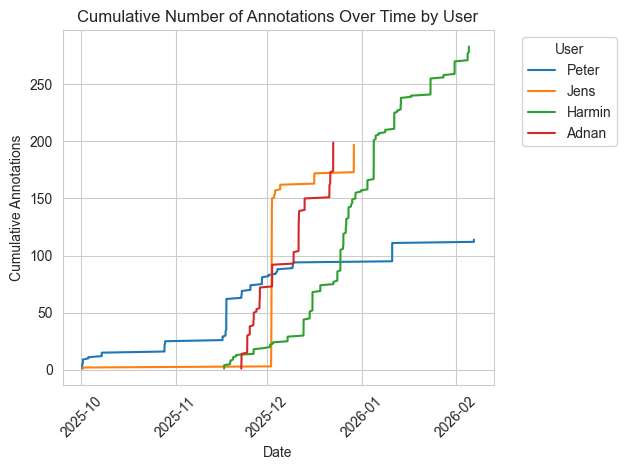

In [11]:
g=sns.lineplot(data=df4f_sorted, x='created_at', y='cumsum', hue='first_name')
# change ticks interval to monthly
from matplotlib.dates import MonthLocator, DateFormatter
g.xaxis.set_major_locator(MonthLocator())
g.xaxis.set_major_formatter(DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
plt.title('Cumulative Number of Annotations Over Time by User')
plt.xlabel('Date')
plt.ylabel('Cumulative Annotations')
plt.legend(title='User', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


# Activity by image

In [39]:
df5=df[['id','patient_id','measure_dataset','created_at','last_modified']]
df5.loc[:,'created_at']=pd.to_datetime(df5['created_at'])
df5.loc[:,'m_len']=df5['measure_dataset'].map(lambda d: len(d))
df5.loc[:,'m_created']=pd.to_datetime(df5['last_modified'])
df5_sorted = df5.sort_values(by='created_at')
df5_sorted['image_cumsum']=df5_sorted['id'].expanding().count()
df5_sorted['m_dataset_cumsum']=df5_sorted.groupby('m_len').cumcount()+1

/var/folders/v5/10wd6_3x1xz6vdd_jj69w80r0000gn/T/ipykernel_19653/1612933745.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df5.loc[:,'m_len']=df5['measure_dataset'].map(lambda d: len(d))
/var/folders/v5/10wd6_3x1xz6vdd_jj69w80r0000gn/T/ipykernel_19653/1612933745.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df5.loc[:,'m_created']=pd.to_datetime(df5['last_modified'])


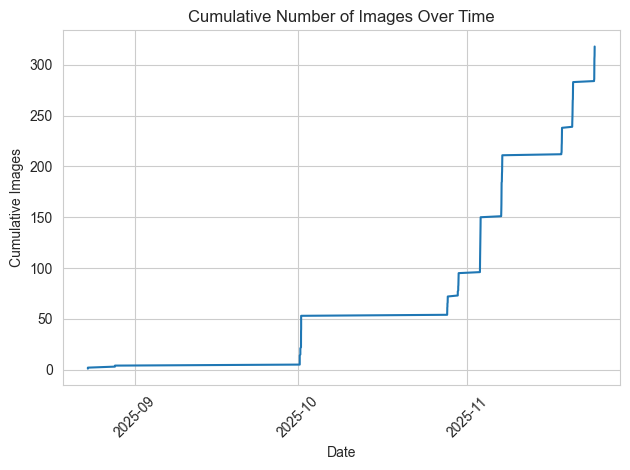

In [35]:
g=sns.lineplot(data=df5_sorted, x='created_at', y='image_cumsum')
# change ticks interval to monthly
from matplotlib.dates import MonthLocator, DateFormatter
g.xaxis.set_major_locator(MonthLocator())
g.xaxis.set_major_formatter(DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
plt.title('Cumulative Number of Images Over Time')
plt.xlabel('Date')
plt.ylabel('Cumulative Images')
plt.tight_layout()
plt.show()


In [40]:
df5_sortedb = df5.sort_values(by='m_created')
df5_sortedb['m_dataset_cumsum']=df5_sortedb.groupby('m_len').cumcount()+1

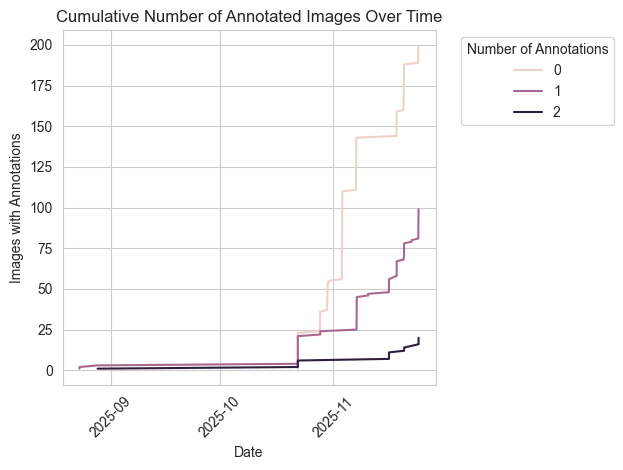

In [42]:
g=sns.lineplot(data=df5_sortedb.explode('m_created'), x='m_created', y='m_dataset_cumsum', hue='m_len')
g.xaxis.set_major_locator(MonthLocator())
g.xaxis.set_major_formatter(DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
plt.title('Cumulative Number of Annotated Images Over Time')
plt.xlabel('Date')
plt.ylabel('Images with Annotations')
plt.legend(title='Number of individual measurements', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()